<a target="_blank" href="https://colab.research.google.com/github/LSSTC-DSFP/Session-27/blob/main/Day4/MLForTimeSeriesPart2.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Machine Learning for Time-Series Data, Part 2: Learning Beyond the Labels

Helen Qu (Flatiron Institute | CCA)

In Part 1 you trained classifiers on the PLAsTiCC training set, but this time we will focus on how the objects with labels are bright and nearby, and the survey is mostly faint and distant. Labels are few and biased, but unlabelled light curves are plentiful.

In this notebook you will:

1. **look at** and **measure** the shift between the labelled set and the survey;
2. see how a classifier like those of Part 1 (**boosted trees** on hand-made features) **fails** on the survey, and where;
3. build a small **transformer** that reads the observations directly (no GP, no grid);
4. **pre-train** it with a self-supervised task (masked reconstruction) on unlabelled light curves from both the labelled set *and* the survey;
5. **adapt** it with labels (linear probe and fine-tuning), and compare it with training from scratch, with all of the labels and with only 10% of them;
6. use the pre-trained representation for **other tasks** (redshift, anomaly detection, similarity search), as a small "foundation model".

**Learning Objectives**

By the end of this notebook you should be able to:

1. Define covariate shift, label shift and new classes, and diagnose them with summary statistics and a domain classifier.
2. Explain how and where a classifier trained only on labelled data fails under shift (S/N, redshift, class mix).
3. Represent an irregular multi-band light curve as a set of tokens for a transformer.
4. Implement and train a masked-reconstruction (self-supervised) objective.
5. Compare linear probing and fine-tuning, and evaluate on in-distribution *and* shifted data.
6. Use learned embeddings for several downstream tasks, and explain what makes a representation "foundational".

*Note on compute* – **Use a GPU runtime** (*Runtime* $\rightarrow$ *Change runtime type* $\rightarrow$ *T4 GPU*). With a GPU, all of the training in this notebook takes a few minutes. Without a GPU, the notebook switches to a smaller `QUICK` configuration (fewer objects and epochs), and the results are noisier.

*Note on the data* – We use the same Hugging Face copy of PLAsTiCC as in Part 1 ([`helenqu/astro-time-series`](https://huggingface.co/datasets/helenqu/astro-time-series)). You may see a warning that `HF_TOKEN` does not exist; you can ignore it.

*Approximate time budget*: Problem 1 (20 min), Problem 2 (10 min), Problem 3 (15 min), Problem 4 (15 min), Problem 5 (15 min), Problem 6 (15 min). Problems marked *Challenge* are for later.

In [1]:
import os
import time
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from huggingface_hub import hf_hub_download
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.linear_model import RidgeCV
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
rng = np.random.default_rng(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK = device.type == "cpu"   # smaller configuration without a GPU
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}" + ("  ->  QUICK mode (no GPU found)" if QUICK else ""))

PyTorch version: 2.14.1+cu130
Device: cuda


In [2]:
%matplotlib inline

## The Data: Labelled Light Curves and Survey Light Curves

We use two data sets:

* the **source** (labelled) data: the PLAsTiCC training set (`train` and `validation` splits, 7,848 objects). It is like a spectroscopically confirmed sample: bright, nearby, and with a mix of WFD and DDF light curves.
* the **target** (survey) data: objects from one file of the PLAsTiCC test set. All of them are WFD objects. We split them into an **unlabelled pool**, which we may use without labels (as a survey would), and an **evaluation set**, whose labels we use *only* to measure performance.

The cells below load both (the target data is streamed: we read only the first `N_TARGET` objects of one 3.3 GB file).

In [3]:
REPO = "helenqu/astro-time-series"
FILES = {"train": "data/train/train_with_metadata.jsonl",
         "validation": "data/validation/val_with_metadata.jsonl"}
TARGET_FILE = "data/test/plasticc_test_lightcurves_02.csv_with_metadata.jsonl"

N_TARGET = 6000 if QUICK else 15000     # survey objects to stream
N_TARGET_EVAL = 2000 if QUICK else 5000 # of which: evaluation set (labels used only for scoring)

CLASS_NAMES = {6: "μLens-Single", 15: "TDE", 16: "EB", 42: "SNII", 52: "SNIax", 53: "Mira",
               62: "SNIbc", 64: "KN", 65: "M-dwarf", 67: "SNIa-91bg", 88: "AGN", 90: "SNIa",
               92: "RRL", 95: "SLSN-I", 991: "μLens-Binary", 992: "ILOT", 993: "CaRT",
               994: "PISN", 995: "μLens-String"}
BANDS = np.array(["u", "g", "r", "i", "z", "y"])
BAND_WV = np.array([3670.69, 4826.85, 6223.24, 7545.98, 8590.90, 9710.28])  # effective wavelengths (Å)
BAND_COLORS = ["#6A00A8", "#1F77B4", "#2CA02C", "#FF7F0E", "#D62728", "#8C564B"]


def unpack_row(row):
    '''One row of the data set -> dict of 1-D arrays (padding removed) and metadata'''
    tw = np.asarray(row["times_wv"], dtype=float)
    lc = np.asarray(row["lightcurve"], dtype=float)
    keep = (lc[:, 1] > 0) & (tw[:, 0] > 0)  # padded entries have t = 0 and flux_err = 0
    value = lambda key: np.nan if row[key] is None else float(row[key])
    return dict(object_id=int(row["object_id"]), label=int(row["label"]),
                t=tw[keep, 0], wv=tw[keep, 1], flux=lc[keep, 0], flux_err=lc[keep, 1],
                photoz=value("hostgal_photoz"), photoz_err=value("hostgal_photoz_err"),
                redshift=value("redshift"), ddf=int(row["ddf_bool"]))


def load_split(split):
    '''Download one split (only the first time) and unpack it'''
    path = hf_hub_download(REPO, FILES[split], repo_type="dataset")
    df = pd.read_json(path, lines=True).drop_duplicates("object_id")
    return [unpack_row(r) for r in df.to_dict("records")]


src_train = load_split("train")
src_val = load_split("validation")
print(f"source: {len(src_train)} train, {len(src_val)} validation")

data/train/train_with_metadata.jsonl: reconstructing file:   0%|          |  0.00B / 73.5MB            

data/train/train_with_metadata.jsonl: downloading bytes:           |  0.00B            

data/validation/val_with_metadata.jsonl: reconstructing file:   0%|          |  0.00B / 8.09MB            

data/validation/val_with_metadata.jsonl: downloading bytes:           |  0.00B            

source: 7066 train, 782 validation


In [4]:
try:
    from datasets import load_dataset
except ImportError:  # `datasets` is installed in Colab; install it if it is missing
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
    from datasets import load_dataset

t0 = time.time()
stream = load_dataset(REPO, data_files={"test": TARGET_FILE}, split="test", streaming=True)
target = [unpack_row(row) for row in stream.take(N_TARGET)]
tgt_eval, tgt_unlab = target[:N_TARGET_EVAL], target[N_TARGET_EVAL:]
print(f"target: {len(tgt_eval)} evaluation, {len(tgt_unlab)} unlabelled ({time.time() - t0:.0f} s)")

README.md:   0%|          | 0.00/4.40k [00:00<?, ?B/s]

target: 5000 evaluation, 10000 unlabelled (79 s)


In [5]:
y_tr = np.array([lc["label"] for lc in src_train])
y_va = np.array([lc["label"] for lc in src_val])
y_te = np.array([lc["label"] for lc in tgt_eval])     # target labels: for scoring only

CLASSES = np.sort(np.unique(y_tr))
y_tr_idx, y_va_idx = np.searchsorted(CLASSES, y_tr), np.searchsorted(CLASSES, y_va)  # class indices 0..13
known_te = np.isin(y_te, CLASSES)
print(f"{len(CLASSES)} source classes; target evaluation objects from other classes: {np.sum(~known_te)}")

14 source classes; target evaluation objects from other classes: 15


## Problem 1) Diagnosing the Shift

We say that there is a **distribution shift** when the training data and the data we apply the model to come from different distributions. Three common cases:

* **covariate shift**: the inputs change (for example: the target objects are fainter), but the relation between a light curve and its class does not;
* **label shift**: the class mix changes;
* **new classes**: the target contains classes that are not in the source at all.

Real shifts are usually a mix. Before you try to fix a shift, look at it and measure it.

**Problem 1a**

Write `plot_lightcurve`, which plots the flux of one object against time, with error bars and a different colour for each band. The band of an observation is the one whose effective wavelength (`BAND_WV`) is closest to `lc["wv"]`. Plot the time relative to the observation with the highest S/N.

Plot one SN Ia from the source training set and one from the target evaluation set. How do they differ?

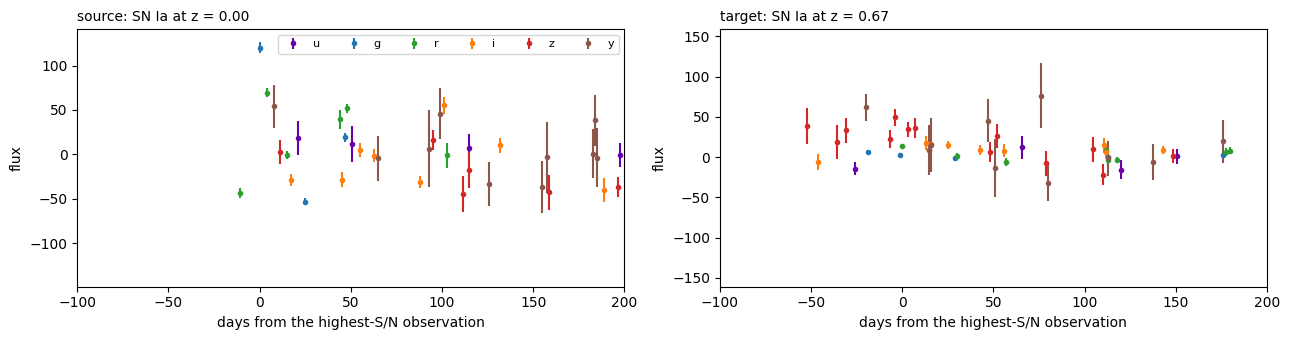

In [45]:
def plot_lightcurve(lc, ax=None, title=""):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3))
    band = np.argmin(np.abs(lc["wv"][:, None] - BAND_WV[None, :]), axis=1)
    t = lc["t"] - lc["t"][np.argmax(lc["flux"] / lc["flux_err"])]
    for b in range(6):
        sel = band == b
        ax.errorbar(t[sel], lc["flux"][sel], lc["flux_err"][sel], fmt="o", ms=3,
                    color=BAND_COLORS[b], label=BANDS[b])
    ax.set_xlabel("days from the highest-S/N observation")
    ax.set_ylabel("flux")
    ax.set_title(title, loc="left", fontsize=10)
    return ax


fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
i_src = 0 # CODE HERE: example from training set
i_tgt = 0 # CODE HERE: example from test set
plot_lightcurve(src_train[i_src], axes[0], f"source: SN Ia at z = {src_train[i_src]['redshift']:.2f}")
plot_lightcurve(tgt_eval[i_tgt], axes[1], f"target: SN Ia at z = {tgt_eval[i_tgt]['redshift']:.2f}")
for ax in axes:
    ax.set_xlim(-100, 200)
axes[0].legend(ncol=6, fontsize=8)
fig.tight_layout()

*write your answer here*

To compare the two data sets with numbers, the function below computes a few simple statistics for each light curve (no GP needed).

In [48]:
def summary_features(lcs):
    '''Simple per-object statistics that describe the survey conditions and the source'''
    rows = []
    for lc in lcs:
        s2n = lc["flux"] / lc["flux_err"]
        rows.append(dict(hostgal_photoz=lc["photoz"], hostgal_photoz_err=lc["photoz_err"],
                         n_obs=len(lc["t"]), duration=np.ptp(lc["t"]),
                         log_peak_snr=np.log10(max(s2n.max(), 1.0)), frac_snr_5=np.mean(s2n > 5),
                         log_peak_flux=np.log10(max(np.abs(lc["flux"]).max(), 1e-3)), ddf=lc["ddf"]))
    return pd.DataFrame(rows)


S_tr, S_va = summary_features(src_train), summary_features(src_val)
S_te, S_un = summary_features(tgt_eval), summary_features(tgt_unlab)
S_tr.describe().round(2)

,hostgal_photoz,hostgal_photoz_err,n_obs,duration,log_peak_snr,frac_snr_5,log_peak_flux,ddf
count,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00
mean,0.36,0.16,171.63,938.49,1.45,0.11,2.39,0.27
std,0.54,0.30,74.13,110.19,0.49,0.15,0.58,0.44
min,0.00,0.00,50.00,755.98,0.00,0.00,1.02,0.00
25%,0.00,0.00,122.00,854.66,1.13,0.02,2.02,0.00
50%,0.21,0.02,136.00,902.59,1.48,0.06,2.28,0.00
75%,0.43,0.12,255.00,1081.11,1.82,0.15,2.63,1.00
max,3.00,1.45,300.00,1094.06,2.33,1.00,6.39,1.00


**Problem 1b**

Plot histograms (normalised to unit area) of `log_peak_snr`, `log_peak_flux`, and `hostgal_photoz` (for extragalactic objects, `hostgal_photoz > 0`) for the source training set and the target unlabelled pool.

Then we provide code that makes a bar chart of the fraction of objects in each class, for the source training set and the target evaluation set (this uses the target labels, which a real survey would not have).

Which kinds of shift do you see?

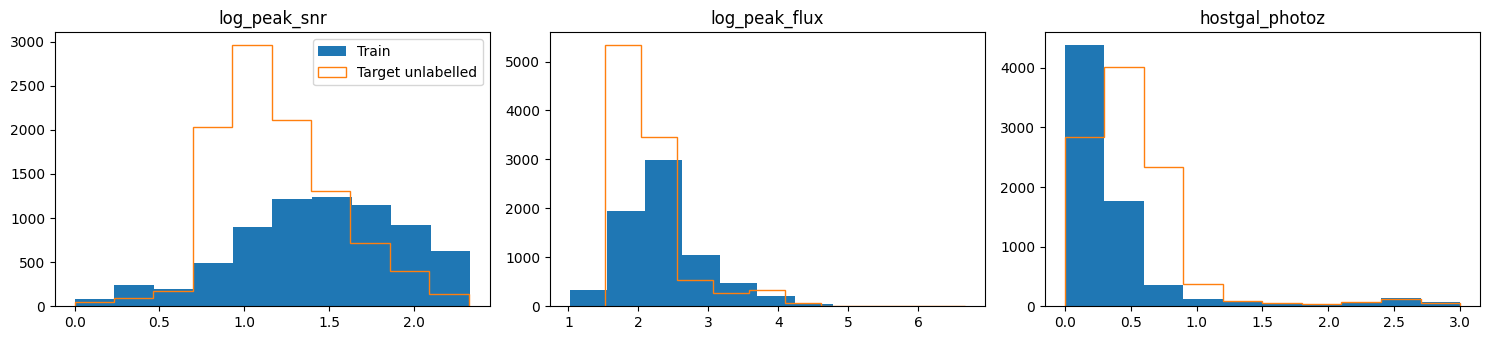

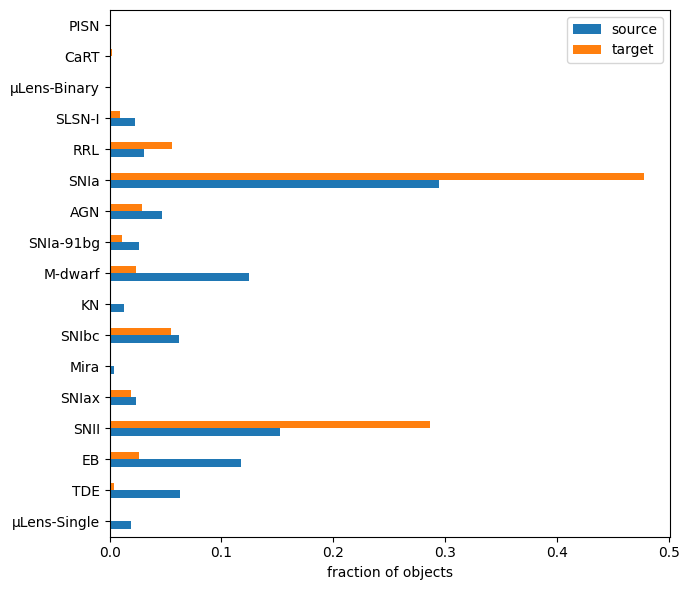

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["log_peak_snr", "log_peak_flux", "hostgal_photoz"]):
    # make histograms of each col in S_tr and S_te (training and test sets)
    ax.hist(S_tr[col], label='Train')
    ax.hist(S_un[col], label='Target unlabelled', histtype='step')
    ax.set_title(col)
axes[0].legend()
fig.tight_layout()

frac = pd.DataFrame({"source": pd.Series(y_tr).value_counts(normalize=True),
                     "target": pd.Series(y_te).value_counts(normalize=True)}).fillna(0).sort_index()
frac.index = [CLASS_NAMES[c] for c in frac.index]
ax = frac.plot.barh(figsize=(7, 6))
ax.set_xlabel("fraction of objects")
plt.tight_layout()

*write your answer here*

## Problem 2) A Classifier from Part 1, Under Shift

In Part 1, gradient-boosted trees on hand-made features were a strong classifier. Here we use a quick version of the same idea without the GP fits (they take too long for this notebook): a few features per light curve that describe its brightness, colours and time scales, plus the host-galaxy photo-z. As in Part 1, the classifier is trained only on the labelled source data.

The next cell computes the features. It also defines the scores that we use for every model in this notebook: the **balanced accuracy** and the **flat-weighted log loss** (as in Part 1), on the source validation set (in distribution, "ID") and on the known-class objects of the target evaluation set (out of distribution, "OOD"). The function `score` adds each model to the table `RESULTS`.

In [64]:
def lc_features(lcs):
    '''A few GP-free features per light curve: brightness, colours, time scales and host photo-z'''
    rows = []
    for lc in lcs:
        t, f = lc["t"], lc["flux"]
        band = np.argmin(np.abs(lc["wv"][:, None] - BAND_WV[None, :]), axis=1)
        peak = max(f.max(), 1e-3)
        i_pk = int(np.argmax(f))
        t_half = t[f >= 0.5 * peak]                       # times with flux above half of the peak
        if len(t_half) > 0:
            rise_time = t[i_pk] - t_half.min()
            decline_time = t_half.max() - t[i_pk]
        else:
            rise_time = 0.0
            decline_time = 0.0
        row = dict(hostgal_photoz=lc["photoz"], hostgal_photoz_err=lc["photoz_err"],
                   log_peak_flux=np.log10(peak),           # brightness
                   min_ratio=f.min() / peak,               # negative excursions (variable stars)
                   rise_time=rise_time,                    # days from half maximum to the peak
                   decline_time=decline_time)              # days from the peak to half maximum
        for b in range(6):                                 # colours: peak flux in each band / peak flux
            fb = f[band == b]
            row[f"peak_ratio_{BANDS[b]}"] = fb.max() / peak if len(fb) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

# print(src_train)


F_tr, F_va, F_te = lc_features(src_train), lc_features(src_val), lc_features(tgt_eval)


def flat_log_loss(y, prob, classes=CLASSES):
    '''Log loss with equal weight for each class (columns of prob in the order of `classes`)'''
    idx = np.searchsorted(classes, y)
    log_p = np.log(np.clip(prob[np.arange(len(y)), idx], 1e-15, 1))
    return -np.mean([log_p[idx == k].mean() for k in np.unique(idx)])


RESULTS = {}


def score(name, prob_va, prob_te):
    '''Scores on the source validation set (ID) and the known-class target objects (OOD)'''
    row = {}
    for split, y, prob in [("ID", y_va, prob_va), ("OOD", y_te[known_te], prob_te[known_te])]:
        row[f"bal. acc. ({split})"] = balanced_accuracy_score(y, CLASSES[prob.argmax(axis=1)])
        row[f"log loss ({split})"] = flat_log_loss(y, prob)
    RESULTS[name] = row
    return pd.DataFrame(RESULTS).T.round(3)


F_tr.describe().round(2)

,hostgal_photoz,hostgal_photoz_err,log_peak_flux,min_ratio,rise_time,decline_time,peak_ratio_u,peak_ratio_g,peak_ratio_r,peak_ratio_i,peak_ratio_z,peak_ratio_y
count,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00,7066.00
mean,0.36,0.16,2.28,-14802.08,145.83,141.65,-574.44,-1480.36,-4294.50,-3690.96,-3433.85,-4033.51
std,0.54,0.30,0.68,915668.88,255.31,235.94,13117.06,47531.74,215335.42,156093.01,136555.57,168003.44
min,0.00,0.00,-3.00,-75869734.38,0.00,0.00,-751720.34,-3367767.58,-16766322.27,-10817614.26,-8618018.56,-10049793.94
25%,0.00,0.00,1.96,-0.76,0.00,0.97,0.08,0.06,0.23,0.31,0.43,0.50
50%,0.21,0.02,2.22,-0.36,9.92,25.02,0.15,0.25,0.56,0.62,0.68,0.80
75%,0.43,0.12,2.56,-0.15,171.20,136.11,0.34,0.64,0.91,0.88,0.92,1.00
max,3.00,1.45,6.39,0.23,1090.81,1075.18,1.00,1.00,1.00,1.00,1.00,1.00


**Problem 2a**

Train a `HistGradientBoostingClassifier` on `F_tr` and the source labels `y_tr` (use `class_weight="balanced"`, `max_iter=200`, `learning_rate=0.05` and `random_state=0`). Score it with `score("boosted trees (features)", ...)`, using `predict_proba` on `F_va` and on `F_te`. (The columns of `predict_proba` are in the order of `trees.classes_`, which is the same as `CLASSES`.)

How large is the gap between ID and OOD?

In [68]:
trees = HistGradientBoostingClassifier(class_weight="balanced", max_iter=200, learning_rate=0.05, random_state=0) # complete
trees.fit(F_tr, y_tr)
assert np.all(trees.classes_ == CLASSES)
score("boosted trees (features)", trees.predict_proba(F_va), trees.predict_proba(F_te)) # complete

,bal. acc. (ID),log loss (ID),bal. acc. (OOD),log loss (OOD)
boosted trees (features),0.666,1.369,0.494,2.65


*write your answer here*

**Problem 2b** – *Where does it fail?*

Make two plots:

1. Bin the objects by `log_peak_snr` (from `S_va` and `S_te`), with the same 5 bins for both sets (use the quantiles of the known-class target objects as bin edges). Plot the balanced accuracy of the trees in each bin, for the source validation set and for the known-class target objects. Skip bins with fewer than 20 objects.
2. Make a bar chart of the true class mix of the target evaluation set and of the class mix that the trees predict for it.

In [ ]:
edges = # complete
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, S, F, y, sel in [("source validation (ID)", S_va, F_va, y_va, np.ones(len(y_va), bool)),
                           ("target, known classes (OOD)", S_te, F_te, y_te, known_te)]:
    # complete
axes[0].set_xlabel(r"$\log_{10}$ peak S/N (bin centre)")
axes[0].set_ylabel("balanced accuracy")
axes[0].legend()

mix = # complete
# complete
fig.tight_layout()

*write your answer here*

## Problem 3) A Transformer for Raw Light Curves

The trees of Problem 2 learn only from labelled light curves, and only through hand-made features. Our next model reads the observations directly. In Problem 4, this lets it learn from the unlabelled survey light curves too.

**Tokens.** A transformer does not need a regular grid: it takes a *set* of tokens, one per observation. Each token holds four numbers:

| | |
| :-- | :-- |
| `t` | time (days) relative to the observation with the highest S/N |
| `band` | band index, 0–5 ($ugrizy$) |
| `flux` | flux divided by the largest \|flux\| of the object |
| `flux_err` | flux uncertainty, divided by the same number |

We keep at most `MAX_LEN` observations per object (the ones closest to the highest-S/N observation) and pad shorter light curves; the boolean array `valid` marks the real observations. Dividing by the largest flux removes the brightness of the object (the shortcut of Problem 2), but the uncertainties still tell the model the S/N.

We also keep the host-galaxy photo-z and its uncertainty as two "extra" inputs for the classifiers.

In [ ]:
MAX_LEN = 160


def tokenize(lc, max_len=MAX_LEN):
    '''
    Light curve -> tokens (max_len, 4) = [t, band, flux, flux_err] and a boolean mask of real tokens
    '''
    t, f, e = lc["t"], lc["flux"], lc["flux_err"]
    band = np.argmin(np.abs(lc["wv"][:, None] - BAND_WV[None, :]), axis=1)
    i_ref = int(np.argmax(f / e))
    if len(t) > max_len:  # keep the max_len observations around the highest-S/N one
        lo = int(np.clip(i_ref - max_len // 2, 0, len(t) - max_len))
        t, f, e, band = t[lo:lo + max_len], f[lo:lo + max_len], e[lo:lo + max_len], band[lo:lo + max_len]
        i_ref -= lo
    scale = max(np.max(np.abs(f)), 1e-3)
    tokens = np.zeros((max_len, 4), dtype=np.float32)
    n = len(t)
    tokens[:n, 0] = t - t[i_ref]
    tokens[:n, 1] = band
    tokens[:n, 2] = f / scale
    tokens[:n, 3] = e / scale
    valid = np.zeros(max_len, dtype=bool)
    valid[:n] = True
    return tokens, valid


def to_arrays(lcs):
    '''Tokens X (N, L, 4), mask V (N, L) and extra inputs E (N, 2) for a list of light curves'''
    X, V = map(np.stack, zip(*[tokenize(lc) for lc in lcs]))
    E = np.array([[lc["photoz"], lc["photoz_err"]] for lc in lcs], dtype=np.float32)
    return X, V, E


X_tr, V_tr, E_tr = to_arrays(src_train)
X_va, V_va, E_va = to_arrays(src_val)
X_te, V_te, E_te = to_arrays(tgt_eval)
X_un, V_un, E_un = to_arrays(tgt_unlab)       # labels never used
print("tokens:", X_tr.shape)

The function below plots the tokens of one object. Compare the tokens of the two SNe Ia of Problem 1a: after normalisation, the two light curves have the same height, but the target one has much larger (relative) error bars.

In [ ]:
def plot_tokens(x, v, ax=None, title=""):
    '''Normalised flux of the valid tokens against time, one colour per band'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3))
    x = x[v]
    for b in range(6):
        sel = x[:, 1] == b
        ax.errorbar(x[sel, 0], x[sel, 2], x[sel, 3], fmt="o", ms=3, color=BAND_COLORS[b], label=BANDS[b])
    ax.set_xlabel("days from the highest-S/N observation")
    ax.set_ylabel("normalised flux")
    ax.set_title(title, loc="left", fontsize=10)
    return ax


fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
plot_tokens(X_tr[i_src], V_tr[i_src], axes[0], "source: SN Ia (tokens)")
plot_tokens(X_te[i_tgt], V_te[i_tgt], axes[1], "target: SN Ia (tokens)")
axes[0].legend(ncol=6, fontsize=8)
fig.tight_layout()

**The model.** Each token becomes a vector of length $d$ (`D_MODEL`), the sum of three embeddings:

$$\mathbf{h}_k = W\,[\,f_k,\ \sigma_k\,] \;+\; \mathbf{b}_{\,{\rm band}_k} \;+\; \mathrm{TE}(t_k),$$

a linear map of the flux and its uncertainty, a learned vector for the band, and a sinusoidal **time encoding** of the (continuous) time,

$$\mathrm{TE}(t) = \big[\sin(\omega_1 t), \ldots, \sin(\omega_{d/2} t),\ \cos(\omega_1 t), \ldots, \cos(\omega_{d/2} t)\big], \qquad \omega_j = 2\pi / P_j,$$

with periods $P_j$ spaced logarithmically between 1 and 1000 days. Self-attention layers then let every observation "look at" every other observation, in any band, without a grid. The padded positions are ignored with a mask. To classify, we average the token vectors (over the real observations only), append the extra inputs (host photo-z), and apply a small fully connected head.

**Problem 3a**

Complete the `forward` method of `TimeEncoding`, and the function `pool` (the mean of `h` over the valid tokens). Then run the test cell.

In [ ]:
D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 64, 4, 2, 128, 0.1


class TimeEncoding(nn.Module):
    '''Sinusoidal encoding of continuous time (days), with periods from 1 to 1000 days'''
    def __init__(self, d_model):
        super().__init__()
        periods = torch.logspace(0, 3, d_model // 2)
        self.register_buffer("omega", 2 * np.pi / periods)

    def forward(self, t):                    # t: (batch, length)
        arg = # complete                     # (batch, length, d_model / 2)
        return # complete


def pool(h, valid):
    '''Mean of h (batch, length, d) over the valid tokens -> (batch, d)'''
    h = # complete: set h to zero at the padded positions (hint: masked_fill)
    return # complete


class LightCurveEncoder(nn.Module):
    '''Tokens (batch, length, 4) -> one vector per token (batch, length, D_MODEL)'''
    def __init__(self, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.value_proj = nn.Linear(2, d_model)          # [flux, flux_err] -> d_model
        self.band_emb = nn.Embedding(6, d_model)         # one learned vector per band
        self.time_enc = TimeEncoding(d_model)
        self.mask_token = nn.Parameter(torch.zeros(d_model))  # replaces hidden values (Problem 4)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, valid, hide=None):
        h = self.value_proj(x[..., 2:4])
        if hide is not None:                             # hide the flux and error of some tokens
            h = torch.where(hide[..., None], self.mask_token.expand_as(h), h)
        h = h + self.band_emb(x[..., 1].long()) + self.time_enc(x[..., 0])
        h = self.encoder(h, src_key_padding_mask=~valid)
        return self.norm(h)


class Classifier(nn.Module):
    '''Encoder + mean pooling + [photo-z, photo-z error] -> class logits'''
    def __init__(self, encoder, n_classes, n_extra=2, d_model=D_MODEL):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Sequential(nn.Linear(d_model + n_extra, 64), nn.ReLU(), nn.Dropout(0.2),
                                  nn.Linear(64, n_classes))

    def forward(self, x, valid, extra):
        z = pool(self.encoder(x, valid), valid)
        return self.head(torch.cat([z, extra], dim=1))

In [ ]:
te = TimeEncoding(8)
assert te(torch.zeros(2, 3)).shape == (2, 3, 8)
assert torch.allclose(te(torch.zeros(1, 1))[0, 0], torch.tensor([0., 0, 0, 0, 1, 1, 1, 1]))
h = torch.arange(6.0).reshape(1, 3, 2)
assert torch.allclose(pool(h, torch.tensor([[True, True, False]])), torch.tensor([[1.0, 2.0]]))
model = Classifier(LightCurveEncoder(), len(CLASSES))
x, v = torch.as_tensor(X_tr[:4]), torch.as_tensor(V_tr[:4])
print("logits:", model(x, v, torch.as_tensor(E_tr[:4])).shape,
      f"| {sum(p.numel() for p in model.parameters()):,} parameters")

The next cell defines the training tools: a function that makes a `DataLoader` from arrays, a training loop with early stopping on the source validation set, and functions for predictions and embeddings. Read it; you do not need to change it. We score every model with `score` from Problem 2, so all results go into the same table as the boosted trees.

In [ ]:
BATCH = 128
FINETUNE_EPOCHS = 6 if QUICK else 15
counts = np.bincount(y_tr_idx, minlength=len(CLASSES))
CLASS_WEIGHTS = torch.tensor(len(y_tr_idx) / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32)


def make_loader(*arrays, shuffle=False, batch_size=BATCH):
    return DataLoader(TensorDataset(*[torch.as_tensor(a) for a in arrays]), batch_size=batch_size,
                      shuffle=shuffle)


val_loader = make_loader(X_va, V_va, E_va, y_va_idx)


def train_classifier(model, train_loader, n_epochs=FINETUNE_EPOCHS, lr=1e-3, freeze_encoder=False):
    '''Class-weighted cross-entropy, AdamW, early stopping on the source validation loss'''
    model.to(device)
    loss_fn = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(device))
    for p in model.encoder.parameters():
        p.requires_grad = not freeze_encoder
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    best, history = (np.inf, None), []
    for epoch in range(n_epochs):
        t0 = time.time()
        model.train()
        if freeze_encoder:
            model.encoder.eval()          # no dropout in a frozen encoder
        for x, v, e, y in train_loader:
            x, v, e, y = x.to(device), v.to(device), e.to(device), y.to(device)
            loss = loss_fn(model(x, v, e), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = np.mean([loss_fn(model(x.to(device), v.to(device), e.to(device)), y.to(device)).item()
                                for x, v, e, y in val_loader])
        history.append(val_loss)
        if val_loss < best[0]:
            best = (val_loss, copy.deepcopy(model.state_dict()))
        print(f"epoch {epoch + 1:2d}: validation loss {val_loss:.3f} ({time.time() - t0:.1f} s)")
    model.load_state_dict(best[1])
    return model


@torch.no_grad()
def predict_proba(model, X, V, E, batch_size=512):
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        x, v, e = [torch.as_tensor(a[i:i + batch_size]).to(device) for a in (X, V, E)]
        out.append(torch.softmax(model(x, v, e), dim=1).cpu().numpy())
    return np.concatenate(out)


@torch.no_grad()
def embed(encoder, X, V, batch_size=512):
    '''Mean-pooled encoder output for every object -> (N, D_MODEL)'''
    encoder.to(device).eval()
    out = []
    for i in range(0, len(X), batch_size):
        x, v = torch.as_tensor(X[i:i + batch_size]).to(device), torch.as_tensor(V[i:i + batch_size]).to(device)
        out.append(pool(encoder(x, v), v).cpu().numpy())
    return np.concatenate(out)

**Problem 3b**

Train a `Classifier` with a new `LightCurveEncoder` *from scratch* on the source training set (make the training loader with `make_loader(X_tr, V_tr, E_tr, y_tr_idx, shuffle=True)`). Score it with `score("scratch", ...)`, using `predict_proba` on the source validation set and on the target evaluation set.

How large is the gap between ID and OOD? Compare with the boosted trees of Problem 2.

In [ ]:
torch.manual_seed(0)
train_loader = # complete
scratch = # complete
score("scratch", # complete

*write your answer here*

## Problem 4) Self-Supervised Pre-Training: Masked Reconstruction

The idea of **self-supervised learning** is to invent a task that needs no labels, but that can only be solved by understanding the data. For light curves, a natural task is **masked reconstruction** (as in BERT for text, MAE for images, and Astromer for light curves): hide the flux of a random 30% of the observations, and train the model to predict the hidden fluxes from the rest. The times and bands of the hidden observations stay visible, so the model knows *where* to predict. To do this well, the model must learn the shapes, time scales and colours of light curves – the same information a classifier needs.

The pre-training task needs no labels, so we can use **all** of the light curves: the source sets *and* the unlabelled target pool. This is the key difference from Problems 2–3: the model now sees faint, high-redshift survey light curves during training.

**Problem 4a**

Complete `masked_loss`:

1. choose the tokens to hide: each *valid* token is hidden with probability `mask_frac`;
2. predict the flux at every token with `model(x, valid, hide)`;
3. return the mean squared error between the prediction and the true normalised flux (`x[..., 2]`), **over the hidden tokens only**.

In [ ]:
MASK_FRAC = 0.3
PRETRAIN_EPOCHS = 6 if QUICK else 20


class MaskedModel(nn.Module):
    '''Encoder + a linear layer that predicts the (normalised) flux of every token'''
    def __init__(self, encoder, d_model=D_MODEL):
        super().__init__()
        self.encoder = encoder
        self.recon = nn.Linear(d_model, 1)

    def forward(self, x, valid, hide):
        return self.recon(self.encoder(x, valid, hide)).squeeze(-1)


def masked_loss(model, x, valid, mask_frac=MASK_FRAC):
    hide = # complete
    pred = # complete
    return # complete

**Problem 4b**

Pre-train a new encoder on all of the light curves (`X_tr`, `X_va` and `X_un`, with their masks) for `PRETRAIN_EPOCHS` epochs with AdamW (learning rate $10^{-3}$). Plot the mean training loss per epoch.

*Note* – this is the longest step (a few minutes with a GPU). If `USE_PRECOMPUTED` is `True` and pre-trained weights are available on Hugging Face, the cell loads them instead.

In [ ]:
USE_PRECOMPUTED = True
WEIGHTS = "pretrained_masked_model.pt"


def pretrain(model, X, V, n_epochs=PRETRAIN_EPOCHS, lr=1e-3):
    '''Masked-reconstruction pre-training of a MaskedModel; returns the mean loss per epoch'''
    model.to(device)
    opt = # complete
    loader = # complete
    history = []
    for epoch in range(n_epochs):
        t0, losses = time.time(), []
        model.train()
        for x, v in loader:
            # complete
            # complete
            # complete
            # complete
            losses.append(loss.item())
        history.append(np.mean(losses))
        print(f"epoch {epoch + 1:2d}: masked-reconstruction loss {history[-1]:.4f} ({time.time() - t0:.1f} s)")
    return history


torch.manual_seed(1)
masked_model = MaskedModel(LightCurveEncoder()).to(device)
if USE_PRECOMPUTED and not os.path.exists(WEIGHTS):
    try:  # pre-trained weights, if the data set provides them
        os.symlink(hf_hub_download(REPO, f"precomputed/{WEIGHTS}", repo_type="dataset"), WEIGHTS)
    except Exception:
        pass
if os.path.exists(WEIGHTS):
    masked_model.load_state_dict(torch.load(WEIGHTS, map_location=device))
    print("loaded the pre-trained weights")
else:
    X_all, V_all = # complete
    pretrain_history = pretrain(masked_model, X_all, V_all)
    torch.save(masked_model.state_dict(), WEIGHTS)
    # complete: plot pretrain_history
pretrained = masked_model.encoder

**Problem 4c**

Look at what the model learned. For two target objects (for example a SN Ia and a SN II), hide 30% of the observations, predict them, and plot the true tokens together with the predictions at the hidden times (use a different marker).

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
torch.manual_seed(3)
for ax, cls in zip(axes, [90, 42]):
    # complete
fig.tight_layout()

*write your answer here*

## Problem 5) Adapting the Pre-Trained Model

There are two standard ways to use a pre-trained encoder for a labelled task:

* **linear probing**: freeze the encoder and train only the head. This tests how much class information is already in the representation, and it cannot destroy what pre-training learned.
* **fine-tuning**: train the head *and* the encoder (usually with a smaller learning rate). This usually gives the best in-distribution results, but it can move the representation towards the (shifted) labelled data.

**Problem 5a**

Train both, starting from copies of `pretrained` (use `copy.deepcopy`). For linear probing use `freeze_encoder=True` and a learning rate of $10^{-3}$; for fine-tuning use a learning rate of $3\times10^{-4}$. Score both, and compare with `scratch`.

In [ ]:
torch.manual_seed(0)
probe = # complete
score("pre-trained + linear probe", # complete

torch.manual_seed(0)
finetuned = # complete
score("pre-trained + fine-tuned", # complete

**Problem 5b** – *Label efficiency*

Labels are the scarcest resource. Repeat the comparison of `scratch` and `pre-trained + fine-tuned` using only 10% of the source training labels (a stratified random subset; use `train_test_split(..., train_size=0.1, stratify=y_tr_idx, random_state=0)` to choose the indices). The pre-training step is unchanged: it never used labels.

Does pre-training matter more when labels are scarce?

In [ ]:
idx_small, _ = # complete
small_loader = # complete
print(f"{len(idx_small)} labelled objects")

torch.manual_seed(0)
scratch_10 = # complete
score("scratch (10% labels)", # complete

torch.manual_seed(0)
finetuned_10 = # complete
score("pre-trained + fine-tuned (10% labels)", # complete

## Problem 6) One Representation, Many Tasks

A **foundation model** is a model trained on broad data (usually without labels) that can be adapted to many downstream tasks. Ours is tiny, but we can test the idea: compute the mean-pooled embedding of every light curve with the pre-trained encoder (no fine-tuning), and use the same embeddings for several tasks with simple models.

In [ ]:
Z_tr = embed(pretrained, X_tr, V_tr)
Z_va = embed(pretrained, X_va, V_va)
Z_te = embed(pretrained, X_te, V_te)
print("embeddings:", Z_tr.shape)

**Problem 6a**

Project the embeddings of the source training set and the target evaluation set onto their first two principal components (fit `PCA` on both together). Make two scatter plots: one coloured by data set (source or target), and one coloured by class (for SN Ia, SN II, RRL, EB, AGN and M-dwarf only).

Do the two data sets overlap? Do the classes separate?

In [ ]:
pca = # complete
P_tr, P_te = # complete

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# complete
fig.tight_layout()

**Problem 6b** – *Redshift from the light curve*

Use the embeddings to estimate the (true) redshift of extragalactic objects: fit `RidgeCV` on the source training set (objects with `hostgal_photoz > 0`; target $\log_{10}(1 + z)$), and predict for the target evaluation set. Plot predicted against true redshift, and compute the scatter of $\Delta z / (1 + z)$.

Where does the regression fail, and why?

In [ ]:
z_tr = np.array([lc["redshift"] for lc in src_train])
z_te = np.array([lc["redshift"] for lc in tgt_eval])
eg_tr, eg_te = E_tr[:, 0] > 0, E_te[:, 0] > 0

reg = # complete
z_pred = # complete
dz = # complete
print(f"target: scatter of dz/(1+z) = {np.std(dz):.3f}, median bias = {np.median(dz):+.3f}")

# complete: plot predicted vs true redshift

*write your answer here*

**Problem 6c** – *Finding new kinds of objects*

The target set contains a few objects from classes that the source does not have. A simple anomaly score: the mean distance from each target object to its $k = 10$ nearest neighbours among the source training embeddings (use `NearestNeighbors`, on embeddings that you first divide by their norm).

Compute the ROC AUC of this score for "unknown class" (`~known_te`) against "known class". Compare it with a classifier-based score, $1 - \max_k p_k$, from the fine-tuned model of Problem 5a. How many unknown-class objects are there? How much would you trust the AUC?

In [ ]:
normed = lambda Z: Z / np.linalg.norm(Z, axis=1, keepdims=True)
nn_index = # complete
dist, _ = # complete
knn_score = # complete

print(f"{np.sum(~known_te)} unknown-class objects in the target evaluation set")
print(f"kNN distance in the pre-trained embedding:  AUC = {roc_auc_score(~known_te, knn_score):.3f}")
print(f"1 - max p (fine-tuned classifier):          AUC = "
      f"{roc_auc_score(~known_te, 1 - prob_te['pre-trained + fine-tuned'].max(axis=1)):.3f}")

*write your answer here*

## References

* Boone, K. 2019, AJ, 158, 257 – avocado (features, boosted trees and physics-based augmentation on PLAsTiCC)
* Devlin, J., et al. 2019, NAACL – BERT (masked language modelling)
* He, K., et al. 2022, CVPR – masked autoencoders for images
* Chen, T., et al. 2020, ICML – SimCLR (contrastive learning)
* Kumar, A., et al. 2022, ICLR – fine-tuning can distort pre-trained features
* Donoso-Oliva, C., et al. 2023, A&A – Astromer (masked pre-training on light curves)
* Qu, H., & Xie, S. M. 2024, ICML – Connect Later (pre-training and targeted augmentations under shift, on PLAsTiCC)
* Bommasani, R., et al. 2021, arXiv:2108.07258 – foundation models